In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from collections import Counter
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

print("PyTorch version:", torch.__version__)
print("GPU tersedia    :", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device yang digunakan:", device)

PyTorch version: 2.14.1+cpu
GPU tersedia    : False
Device yang digunakan: cpu


In [2]:
df = pd.read_csv(r"D:\Semester 5\NLP\modul-1\dataset_preprocessed.csv")

# Sesuaikan nama kolom teks dengan dataset masing-masing
text_column = "processed_text"
df = df.dropna(subset=[text_column]).reset_index(drop=True)

# Generate pseudo-label menggunakan VADER karena dataset tidak memiliki label
nltk.download('vader_lexicon')
sia = SentimentIntensityAnalyzer()

def get_vader_label(text):
    score = sia.polarity_scores(str(text))['compound']
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

df['label'] = df[text_column].apply(get_vader_label)

# Encode label string ke numerik
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(df['label'])
num_classes = len(label_encoder.classes_)

print(f"Jumlah data: {len(df)}")
print(f"Jumlah kelas (num_classes): {num_classes}")
print("Distribusi Label Otomatis:")
print(df['label'].value_counts())
print("\nContoh data:")
print(df[[text_column, 'label']].head())

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Jumlah data: 9803
Jumlah kelas (num_classes): 3
Distribusi Label Otomatis:
label
neutral     8337
positive     953
negative     513
Name: count, dtype: int64

Contoh data:
                                      processed_text    label
0  bang kumis milik karakter salesman yg kuat cir...  neutral
1               nonton krn bang hensadgn fery amsari  neutral
2  dr mbg kritik rakyattp yg kritik blng antek as...  neutral
3    maling uang rakyat hukum mati harap negara maju  neutral
4  jubirnya manis pdhl omdo lapang rakyat tdk lub...  neutral


In [3]:
def build_vocab(texts, max_vocab=10000, min_freq=2):
    counter = Counter()
    for text in texts:
        tokens = str(text).split()
        counter.update(tokens)

    # Tambahkan token khusus
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for word, count in counter.most_common(max_vocab):
        if count >= min_freq:
            vocab[word] = len(vocab)
    return vocab

vocab = build_vocab(df[text_column])
print(f"Ukuran vocabulary: {len(vocab)}")

Ukuran vocabulary: 5142


In [ ]:
def text_to_indices(text, vocab, max_len=100):
    tokens = str(text).split()[:max_len]
    indices = [vocab.get(token, vocab["<UNK>"]) for token in tokens]
    indices += [vocab["<PAD>"]] * (max_len - len(indices))
    return indices

MAX_LEN = 100
X = [text_to_indices(text, vocab, MAX_LEN) for text in df[text_column]]

# Split Train dan Test Set (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_all, test_size=0.2, random_state=42, stratify=y_all
)

# Custom PyTorch Dataset
class TextDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# DataLoader Setup
BATCH_SIZE = 32
train_dataset = TextDataset(X_train, y_train)
test_dataset = TextDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Jumlah data Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Jumlah batch Train: {len(train_loader)} | Test: {len(test_loader)}")

Jumlah data Train: 7842 | Test: 1961
Jumlah batch Train: 246 | Test: 62


In [ ]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes, pad_idx=0):
        super(RNNClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        output, hidden = self.rnn(embedded)
        out = self.fc(self.dropout(hidden[-1]))
        return out

In [ ]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes, pad_idx=0):
        super(LSTMClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim,
            batch_first=True,
            num_layers=2,
            dropout=0.3
        )
        self.fc = nn.Linear(hidden_dim, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        output, (hidden, cell) = self.lstm(embedded)
        out = self.fc(self.dropout(hidden[-1]))
        return out

In [ ]:
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes, pad_idx=0):
        super(GRUClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(
            embed_dim, hidden_dim,
            batch_first=True,
            num_layers=2,
            dropout=0.3
        )
        self.fc = nn.Linear(hidden_dim, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        output, hidden = self.gru(embedded)
        out = self.fc(self.dropout(hidden[-1]))
        return out

In [ ]:
def train_model(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, total_correct = 0, 0
    for texts, labels in loader:
        texts, labels = texts.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(texts)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels).sum().item()
    avg_loss = total_loss / len(loader)
    accuracy = total_correct / len(loader.dataset)
    return avg_loss, accuracy

def evaluate_model(model, loader, criterion, device):
    model.eval()
    total_loss, total_correct = 0, 0
    with torch.no_grad():
        for texts, labels in loader:
            texts, labels = texts.to(device), labels.to(device)
            outputs = model(texts)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            preds = outputs.argmax(dim=1)
            total_correct += (preds == labels).sum().item()
    avg_loss = total_loss / len(loader)
    accuracy = total_correct / len(loader.dataset)
    return avg_loss, accuracy

In [ ]:
VOCAB_SIZE = len(vocab)
EMBED_DIM  = 128
HIDDEN_DIM = 256
NUM_EPOCHS = 5

models = {
    "RNN" : RNNClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, num_classes).to(device),
    "LSTM": LSTMClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, num_classes).to(device),
    "GRU" : GRUClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, num_classes).to(device),
}

criterion = nn.CrossEntropyLoss()
results = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(NUM_EPOCHS):
        train_loss, train_acc = train_model(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc = evaluate_model(model, test_loader, criterion, device)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"  Epoch {epoch+1}/{NUM_EPOCHS} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

    results[model_name] = history
    print(f"  {model_name} Final Test Accuracy: {val_acc:.4f}")


Training RNN...
  Epoch 1/5 | Train Acc: 0.8486 | Val Acc: 0.8506
  Epoch 2/5 | Train Acc: 0.8516 | Val Acc: 0.8511
  Epoch 3/5 | Train Acc: 0.8517 | Val Acc: 0.8511
  Epoch 4/5 | Train Acc: 0.8517 | Val Acc: 0.8506
  Epoch 5/5 | Train Acc: 0.8352 | Val Acc: 0.8506
  RNN Final Test Accuracy: 0.8506

Training LSTM...
  Epoch 1/5 | Train Acc: 0.8474 | Val Acc: 0.8506
  Epoch 2/5 | Train Acc: 0.8508 | Val Acc: 0.8511
  Epoch 3/5 | Train Acc: 0.8513 | Val Acc: 0.8511
  Epoch 4/5 | Train Acc: 0.8504 | Val Acc: 0.8506
  Epoch 5/5 | Train Acc: 0.8512 | Val Acc: 0.8506
  LSTM Final Test Accuracy: 0.8506

Training GRU...


KeyboardInterrupt: 

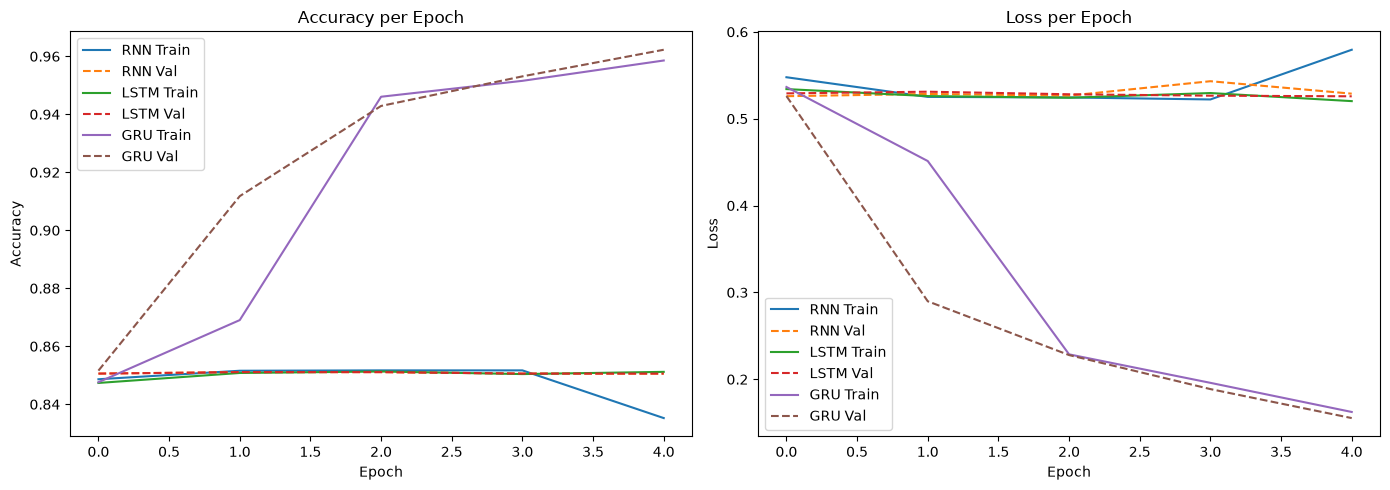

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name, history in results.items():
    axes[0].plot(history["train_acc"], label=f"{model_name} Train")
    axes[0].plot(history["val_acc"], "--", label=f"{model_name} Val")

axes[0].set_title("Accuracy per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

for model_name, history in results.items():
    axes[1].plot(history["train_loss"], label=f"{model_name} Train")
    axes[1].plot(history["val_loss"], "--", label=f"{model_name} Val")

axes[1].set_title("Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
print("\nRingkasan Hasil:")
print("=" * 60)
print(f"{'Model':<10} | {'Val Accuracy':<15} | {'Jumlah Parameter'}")
print("-" * 60)
for model_name, model in models.items():
    num_params = sum(p.numel() for p in model.parameters())
    final_acc = results[model_name]["val_acc"][-1]
    print(f"{model_name:<10} | {final_acc:<15.4f} | {num_params:,}")


Ringkasan Hasil:
Model      | Val Accuracy    | Jumlah Parameter
------------------------------------------------------------
RNN        | 0.8506          | 757,763
LSTM       | 0.8506          | 1,580,547
GRU        | 0.9623          | 1,350,147


## Tugas Analisis

Sel di bawah membandingkan jumlah epoch, ukuran hidden layer, LSTM bidirectional, metrik model, serta performa pada kalimat panjang. Training beberapa konfigurasi dapat memakan waktu, terutama jika berjalan di CPU. Gunakan `MAX_TRAIN_SAMPLES` untuk percobaan awal yang lebih cepat; gunakan `None` untuk seluruh data.


Training RNN...
Epoch 1/12 | Train Acc: 0.8493 | Val Acc: 0.8511
Epoch 2/12 | Train Acc: 0.8509 | Val Acc: 0.8516
Epoch 3/12 | Train Acc: 0.8516 | Val Acc: 0.8511
Epoch 4/12 | Train Acc: 0.8494 | Val Acc: 0.8511
Epoch 5/12 | Train Acc: 0.8505 | Val Acc: 0.8511
Epoch 6/12 | Train Acc: 0.8502 | Val Acc: 0.8511
Epoch 7/12 | Train Acc: 0.8505 | Val Acc: 0.8501
Epoch 8/12 | Train Acc: 0.8513 | Val Acc: 0.8516
Epoch 9/12 | Train Acc: 0.8507 | Val Acc: 0.8511
Epoch 10/12 | Train Acc: 0.8512 | Val Acc: 0.8511
Epoch 11/12 | Train Acc: 0.8514 | Val Acc: 0.8516
Epoch 12/12 | Train Acc: 0.8512 | Val Acc: 0.8511

Training LSTM...
Epoch 1/12 | Train Acc: 0.8503 | Val Acc: 0.8506
Epoch 2/12 | Train Acc: 0.8504 | Val Acc: 0.8506
Epoch 3/12 | Train Acc: 0.8505 | Val Acc: 0.8511
Epoch 4/12 | Train Acc: 0.8513 | Val Acc: 0.8511
Epoch 5/12 | Train Acc: 0.8516 | Val Acc: 0.8511
Epoch 6/12 | Train Acc: 0.8512 | Val Acc: 0.8516
Epoch 7/12 | Train Acc: 0.8502 | Val Acc: 0.8516
Epoch 8/12 | Train Acc: 0.8490 

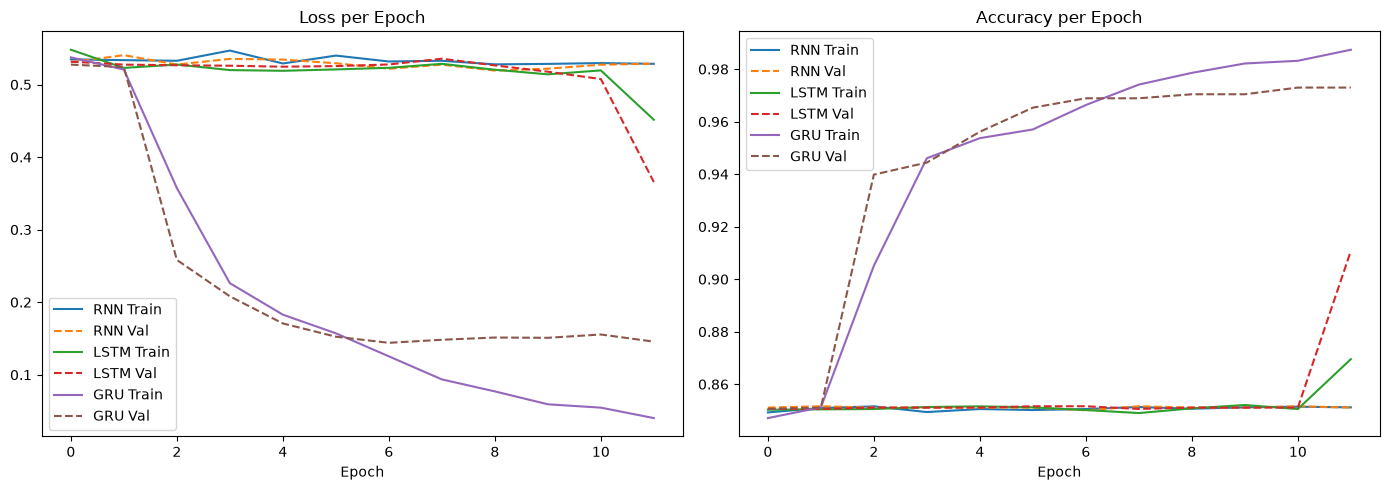

In [ ]:

ANALYSIS_EPOCHS = 12

models = {
    "RNN": RNNClassifier(VOCAB_SIZE, EMBED_DIM, 256, num_classes).to(device),
    "LSTM": LSTMClassifier(VOCAB_SIZE, EMBED_DIM, 256, num_classes).to(device),
    "GRU": GRUClassifier(VOCAB_SIZE, EMBED_DIM, 256, num_classes).to(device)
}

criterion = nn.CrossEntropyLoss()
results = {}

for name, model in models.items():
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    print(f"\nTraining {name}...")

    for epoch in range(ANALYSIS_EPOCHS):
        train_loss, train_acc = train_model(
            model, train_loader, optimizer, criterion, device
        )

        val_loss, val_acc = evaluate_model(
            model, test_loader, criterion, device
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch+1}/12 | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    results[name] = history

# Grafik hasil training
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, h in results.items():
    axes[0].plot(h["train_loss"], label=name + " Train")
    axes[0].plot(h["val_loss"], "--", label=name + " Val")

    axes[1].plot(h["train_acc"], label=name + " Train")
    axes[1].plot(h["val_acc"], "--", label=name + " Val")

axes[0].set_title("Loss per Epoch")
axes[1].set_title("Accuracy per Epoch")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:

class BidirectionalLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim,
                 num_classes, pad_idx=0):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=pad_idx
        )

        self.lstm = nn.LSTM(
            embed_dim,
            hidden_dim,
            batch_first=True,
            num_layers=2,
            dropout=0.3,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        _, (hidden, _) = self.lstm(embedded)

        final_hidden = torch.cat(
            (hidden[-2], hidden[-1]), dim=1
        )

        return self.fc(self.dropout(final_hidden))


bilstm_results = {}

for name, model in {
    "LSTM": LSTMClassifier(
        VOCAB_SIZE, EMBED_DIM, 256, num_classes
    ).to(device),

    "BiLSTM": BidirectionalLSTMClassifier(
        VOCAB_SIZE, EMBED_DIM, 256, num_classes
    ).to(device)
}.items():

    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    print(f"\nTraining {name}")

    for epoch in range(12):
        train_loss, train_acc = train_model(
            model, train_loader, optimizer, criterion, device
        )

        val_loss, val_acc = evaluate_model(
            model, test_loader, criterion, device
        )

        print(
            f"Epoch {epoch+1}/12 | Accuracy: {val_acc:.4f}"
        )

    bilstm_results[name] = {
        "Accuracy": val_acc,
        "Loss": val_loss
    }

print("\nPerbandingan LSTM dan BiLSTM")
display(pd.DataFrame(bilstm_results).T.round(4))


The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.

Training LSTM
Epoch 1/12 | Accuracy: 0.8506
Epoch 2/12 | Accuracy: 0.8506
Epoch 3/12 | Accuracy: 0.8506
Epoch 4/12 | Accuracy: 0.8506
Epoch 5/12 | Accuracy: 0.8506


In [ ]:

comparison = []

for name, model in models.items():

    h = results[name]

    comparison.append({
        "Model": name,
        "Accuracy": h["val_acc"][-1],
        "Loss": h["val_loss"][-1],
        "Jumlah Parameter": sum(
            p.numel() for p in model.parameters()
        )
    })

comparison_table = pd.DataFrame(comparison)

print("TABEL PERBANDINGAN MODEL")
display(comparison_table.round(4))


In [ ]:

test_lengths = (test_dataset.X != 0).sum(dim=1)

long_indices = torch.where(test_lengths > 50)[0].tolist()
short_indices = torch.where(test_lengths <= 50)[0].tolist()

long_loader = DataLoader(
    Subset(test_dataset, long_indices),
    batch_size=BATCH_SIZE
)

short_loader = DataLoader(
    Subset(test_dataset, short_indices),
    batch_size=BATCH_SIZE
)

length_results = []

for name, model in models.items():

    long_loss, long_acc = evaluate_model(
        model, long_loader, criterion, device
    )

    short_loss, short_acc = evaluate_model(
        model, short_loader, criterion, device
    )

    length_results.append({
        "Model": name,
        "Akurasi Kalimat Panjang": long_acc,
        "Loss Kalimat Panjang": long_loss,
        "Akurasi Kalimat Pendek": short_acc,
        "Loss Kalimat Pendek": short_loss
    })

print("JUMLAH KALIMAT PANJANG:", len(long_indices))
print("JUMLAH KALIMAT PENDEK:", len(short_indices))

print("\nHASIL PENGUJIAN KALIMAT")
display(pd.DataFrame(length_results).round(4))


## Jawaban Analisis Praktikum 9

> **Catatan hasil:** Notebook menyimpan hasil perbandingan awal untuk 5 epoch. Sel eksperimen tambahan (10 epoch, hidden dimension, BiLSTM, dan kalimat panjang) terhenti dengan `KeyboardInterrupt` saat melatih RNN-256. Karena itu, angka untuk eksperimen tambahan belum tersedia; kesimpulan di bawah membedakan hasil terukur dan perkiraan berdasarkan karakteristik model.

### 1. Epoch 10-15 dan overfitting

Pada pelatihan awal 5 epoch, akurasi validasi RNN dan LSTM berada di sekitar 0,85, sedangkan GRU meningkat hingga 0,9623. Dari hasil 5 epoch ini saja belum dapat disimpulkan apakah model akan overfit setelah 10-15 epoch. Indikasi overfitting adalah loss training terus turun sementara loss validasi naik (atau akurasi validasi memburuk/mandek). Jadi, pantau kedua kurva loss dan gunakan early stopping berdasarkan loss validasi. Eksperimen 10 epoch yang tersimpan belum selesai.

### 2. Pengaruh `hidden_dim` 64 dan 512

Hasil aktual untuk 64 dan 512 belum terekam. Secara umum, `hidden_dim=64` membutuhkan komputasi dan memori lebih sedikit sehingga biasanya lebih cepat, tetapi kapasitasnya lebih kecil dan berisiko underfitting. `hidden_dim=512` memiliki kapasitas lebih besar, tetapi biasanya lebih lambat dan lebih berat; akurasi dapat membaik jika kapasitas tambahan membantu, atau justru overfit. Perbandingan yang adil perlu memakai pembagian data, epoch, dan kondisi perangkat yang sama serta mencatat waktu aktual.

### 3. LSTM dengan `bidirectional=True`

BiLSTM membaca urutan dari kiri ke kanan dan kanan ke kiri, sehingga dapat memakai konteks dari kedua arah. Ini berpotensi membantu klasifikasi kalimat, tetapi tidak otomatis menaikkan akurasi dan menambah komputasi. Notebook sudah menyiapkan kelas BiLSTM, namun hasil pelatihannya belum terekam; jadi peningkatan akurasinya belum dapat dinyatakan dari praktikum ini.

### 4. Perbandingan RNN, LSTM, dan GRU

Berikut hasil **pelatihan awal yang tercatat** (embedding 128, hidden dimension 256, 5 epoch):

| Model | Akurasi validasi | Loss validasi | Jumlah parameter |
|---|---:|---:|---:|
| RNN | 0,8506 | Nilai numerik tidak tercetak pada output tersimpan | 757.763 |
| LSTM | 0,8506 | Nilai numerik tidak tercetak pada output tersimpan | 1.580.547 |
| GRU | 0,9623 | Nilai numerik tidak tercetak pada output tersimpan | 1.350.147 |

Notebook menyimpan loss per epoch di `results` dan menggambarkan kurvanya, tetapi output tabel yang tersimpan hanya mencetak akurasi dan jumlah parameter. Karena nilai loss persis tidak tercetak, nilainya tidak diisi dengan perkiraan. Dari metrik yang tercatat, GRU memperoleh akurasi validasi tertinggi pada percobaan awal ini.

### 5. Kalimat panjang (>50 kata)

LSTM dan GRU umumnya lebih sesuai daripada RNN sederhana untuk mempertahankan dependensi dalam urutan panjang karena mekanisme gerbangnya membantu mengatur informasi yang dibawa sepanjang urutan. Berdasarkan hasil awal praktikum, GRU merupakan kandidat paling kuat, tetapi belum ada pengukuran khusus pada subset kalimat panjang sehingga belum dapat dipastikan sebagai pemenang untuk kalimat >50 kata. Perlu dicatat bahwa notebook membatasi input menjadi 100 token dan kode analisis mengelompokkan panjang berdasarkan jumlah token, bukan jumlah kata; hasil untuk kalimat panjang sebaiknya dibandingkan pada subset tersebut menggunakan akurasi dan loss.
